In [86]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import textwrap

import statsmodels.api as sm
import statsmodels.formula.api as smf

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from statsmodels.graphics.mosaicplot import mosaic

In [87]:
csv_files = glob.glob('extended_county_results/extended_results_*.csv')

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")

df.columns

Combined dataframe shape: (6908, 19)


Index(['id', 'timestamp', 'model', 'county_type', 'role', 'state',
       'demographic_context', 'capacity_context', 'trade_off_frame', 'pair',
       'option_1', 'option_2', 'selected_choice', 'response_text',
       'infection_rate_selected', 'npi_level_selected',
       'infection_rate_non_selected', 'npi_level_non_selected', 'temperature'],
      dtype='object')

In [88]:
# Replace NaN with "None" string in specified columns
columns_to_fill = ['state', 'demographic_context', 'trade_off_frame', 'capacity_context']
df[columns_to_fill] = df[columns_to_fill].fillna('None')


In [89]:
# Create is_bad_choice column
df['is_bad_choice'] = (
    (df['infection_rate_selected'] > df['infection_rate_non_selected']) & 
    (df['npi_level_selected'] >= df['npi_level_non_selected'])
)

df['is_bad_choice'].value_counts()

is_bad_choice
False    5195
True     1713
Name: count, dtype: int64

In [90]:
df['infection_preference'] = (df['infection_rate_selected'] - df['infection_rate_non_selected'])

In [91]:
df['npi_preference'] = (df['npi_level_selected'] - df['npi_level_non_selected'])

In [92]:
def generate_bradley_terry_model(response_col, df=df, context_cols=None, use_percentage=False):
    # Set high DPI for Jupyter notebook
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 150

    sns.set_theme(style='whitegrid')

    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line

    if context_cols is None:
        context_cols = ['state', 'demographic_context', 'county_type', 'model', 
                        'trade_off_frame', 'capacity_context', 'role']

    results = []
    for col in context_cols:
        grouped = df.groupby(col)[response_col]
        for name, group in grouped:
            if len(group) > 0:
                mean_val = group.mean()
                
                # Convert to percentage if requested
                if use_percentage:
                    mean_val = mean_val * 100
                    se = stats.sem(group) * 100
                else:
                    se = stats.sem(group)
                
                ci = se * 1.96
                results.append({
                    'context': col,
                    'level': str(name),
                    'mean': mean_val,
                    'ci_low': mean_val - ci,
                    'ci_high': mean_val + ci,
                    'n': len(group)
                })

    plot_df = pd.DataFrame(results)
    overall_mean = df[response_col].mean()
    
    # Convert overall mean to percentage if requested
    if use_percentage:
        overall_mean = overall_mean * 100

    # Sort within context
    plot_df = plot_df.sort_values(['context', 'mean'], ascending=[True, False])

    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))

    plot_df['level_wrapped'] = plot_df['level'].apply(wrap_label)

    # Create separate plot for each context
    contexts = plot_df['context'].unique()
    
    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''

    for ctx in contexts:
        subset = plot_df[plot_df['context'] == ctx].reset_index(drop=True)
        subset['y_pos'] = range(len(subset))
        
        # Adjust figure height based on number of items
        fig_height = max(4, len(subset) * 0.5)
        fig, ax = plt.subplots(figsize=(10, fig_height))
        
        # Plot error bars
        for _, row in subset.iterrows():
            ax.plot([row['ci_low'], row['ci_high']], [row['y_pos'], row['y_pos']], 
                    'o-', color='#d62728', linewidth=3, markersize=10,
                    markerfacecolor='black', markeredgecolor='black', markeredgewidth=1.5)
        
        # Vertical mean line
        ax.axvline(overall_mean, color='black', linestyle='--', linewidth=2, alpha=0.7,
                   label=f'Overall mean = {overall_mean:.2f}{unit}')
        
        # Labels with wrapping
        ax.set_yticks(subset['y_pos'])
        ax.set_yticklabels(subset['level_wrapped'], fontsize=13)
        
        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% with 95% CI)'
        
        ax.set_xlabel(xlabel, fontsize=14, fontweight='bold')
        ax.set_title(f'{response_col} by {ctx}', fontsize=16, fontweight='bold', pad=15)
        ax.grid(True, axis='x', alpha=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=11, loc='best')
        
        # Increase tick label size
        ax.tick_params(axis='x', labelsize=12)
        
        plt.tight_layout()
        plt.show()

    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")


# Example usage:
# For raw values (like infection_rate_selected):
# generate_bradley_terry_model('infection_rate_selected', df=df)

# For percentage values (like is_bad_choice which is 0/1):
# generate_bradley_terry_model('is_bad_choice', df=df, use_percentage=True)


In [ ]:
generate_bradley_terry_model('infection_rate_selected')

In [102]:
def generate_grouped_bradley_terry(response_col, primary_context, secondary_context, 
                                    df=df, use_percentage=False, 
                                    max_label_length=30,
                                    group_spacing=1.0,
                                    within_group_spacing=0.15):
    """
    Generate Bradley-Terry style plots with secondary grouping shown via colors.
    
    Parameters:
    -----------
    response_col : str
        Response variable (e.g., 'infection_preference')
    primary_context : str
        Main grouping variable for y-axis (e.g., 'trade_off_frame')
    secondary_context : str
        Secondary grouping shown via colors (e.g., 'model')
    df : DataFrame
        The dataframe containing the data
    use_percentage : bool
        If True, multiply values by 100 for percentage display
    max_label_length : int
        Maximum characters per line for y-axis labels (default: 30)
    group_spacing : float
        Vertical space between primary groups (default: 1.0)
    within_group_spacing : float
        Vertical space between secondary items within a group (default: 0.15)
    """
    
    # Set high DPI
    plt.rcParams['figure.dpi'] = 150
    sns.set_theme(style='whitegrid')
    
    # Wrap labels function
    def wrap_label(text, max_len=max_label_length):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))
    
    results = []
    for primary_val in df[primary_context].unique():
        for secondary_val in df[secondary_context].unique():
            subset = df[(df[primary_context] == primary_val) & 
                       (df[secondary_context] == secondary_val)]
            
            if len(subset) > 0:
                mean_val = subset[response_col].mean()
                
                if use_percentage:
                    mean_val = mean_val * 100
                    se = stats.sem(subset[response_col]) * 100
                else:
                    se = stats.sem(subset[response_col])
                
                ci = se * 1.96
                results.append({
                    'primary': str(primary_val),
                    'primary_wrapped': wrap_label(str(primary_val)),
                    'secondary': str(secondary_val),
                    'mean': mean_val,
                    'ci_low': mean_val - ci,
                    'ci_high': mean_val + ci,
                    'n': len(subset)
                })
    
    plot_df = pd.DataFrame(results)
    overall_mean = df[response_col].mean()
    
    if use_percentage:
        overall_mean = overall_mean * 100
    
    # Sort by primary, then secondary
    plot_df = plot_df.sort_values(['primary', 'secondary'], ascending=[True, True])
    
    # Get unique values
    primary_vals = plot_df['primary'].unique()
    secondary_vals = plot_df['secondary'].unique()
    
    # Create color palette
    colors = sns.color_palette("husl", len(secondary_vals))
    color_map = dict(zip(secondary_vals, colors))
    
    # Set unit label
    unit = '%' if use_percentage else ''
    
    # Calculate y positions with custom spacing
    y_positions = {}
    y_labels = {}
    current_y = 0
    
    for i, primary_val in enumerate(primary_vals):
        subset = plot_df[plot_df['primary'] == primary_val]
        n_secondary = len(subset)
        
        # Center position for this primary group
        center_y = current_y + (n_secondary - 1) * within_group_spacing / 2
        y_labels[center_y] = subset['primary_wrapped'].iloc[0]
        
        # Assign y positions to each secondary value
        for j, (_, row) in enumerate(subset.iterrows()):
            y_pos = current_y + j * within_group_spacing
            y_positions[f"{row['primary']}_{row['secondary']}"] = y_pos
        
        # Move to next group
        current_y += (n_secondary - 1) * within_group_spacing + group_spacing
    
    # Adjust figure height based on total span
    fig_height = max(6, current_y * 0.4)
    fig, ax = plt.subplots(figsize=(12, fig_height))
    
    # Plot each point
    for _, row in plot_df.iterrows():
        y_pos = y_positions[f"{row['primary']}_{row['secondary']}"]
        color = color_map[row['secondary']]
        
        # Plot error bar
        ax.plot([row['ci_low'], row['ci_high']], [y_pos, y_pos],
               'o-', color=color, linewidth=2.5, markersize=8,
               markerfacecolor=color, markeredgecolor='black', markeredgewidth=1)
    
    # Overall mean line
    ax.axvline(overall_mean, color='black', linestyle='--', linewidth=2, alpha=0.7,
               label=f'Overall mean = {overall_mean:.2f}{unit}', zorder=0)
    
    # Y-axis labels at group centers
    ax.set_yticks(list(y_labels.keys()))
    ax.set_yticklabels(list(y_labels.values()), fontsize=13)
    
    # Labels and title
    xlabel = f'{response_col} (Mean with 95% CI)'
    if use_percentage:
        xlabel = f'{response_col} (% with 95% CI)'
    
    ax.set_xlabel(xlabel, fontsize=14, fontweight='bold')
    ax.set_ylabel(primary_context.replace('_', ' ').title(), fontsize=14, fontweight='bold')
    ax.set_title(f'{response_col} by {primary_context} (grouped by {secondary_context})',
                 fontsize=16, fontweight='bold', pad=15)
    
    # Grid and legend
    ax.grid(True, axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    
    # Create custom legend for secondary context colors
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', 
                             markerfacecolor=color_map[val], markersize=8,
                             markeredgecolor='black', markeredgewidth=1,
                             label=val)
                      for val in secondary_vals]
    legend_elements.append(Line2D([0], [0], color='black', linestyle='--', 
                                  linewidth=2, label=f'Overall mean'))
    
    ax.legend(handles=legend_elements, fontsize=11, loc='best',
              title=secondary_context.replace('_', ' ').title(),
              frameon=True, fancybox=True, shadow=True)
    
    # Increase tick label size
    ax.tick_params(axis='x', labelsize=12)
    
    plt.tight_layout()
    plt.show()
    
    '''
    # Print summary
    print(f"\n{'='*60}")
    print(f"GROUPED ANALYSIS")
    print(f"{'='*60}")
    print(f"Response variable: {response_col}")
    print(f"Primary grouping: {primary_context}")
    print(f"Secondary grouping: {secondary_context}")
    print(f"Overall mean: {overall_mean:.2f}{unit}")
    print(f"Labels wrapped at {max_label_length} characters per line")
    print(f"Group spacing: {group_spacing}")
    print(f"Within-group spacing: {within_group_spacing}")
    print(f"\nTotal combinations: {len(plot_df)}")
    
    # Print statistics by group
    print(f"\n{'='*60}")
    print(f"SUMMARY BY {primary_context.upper()}")
    print(f"{'='*60}")
    for primary_val in primary_vals:
        subset = plot_df[plot_df['primary'] == primary_val]
        print(f"\n{primary_val}:")
        for _, row in subset.iterrows():
            print(f"  {row['secondary']:20s} | Mean: {row['mean']:7.2f}{unit} | "
                  f"CI: [{row['ci_low']:6.2f}, {row['ci_high']:6.2f}] | N: {row['n']:4.0f}")
    '''


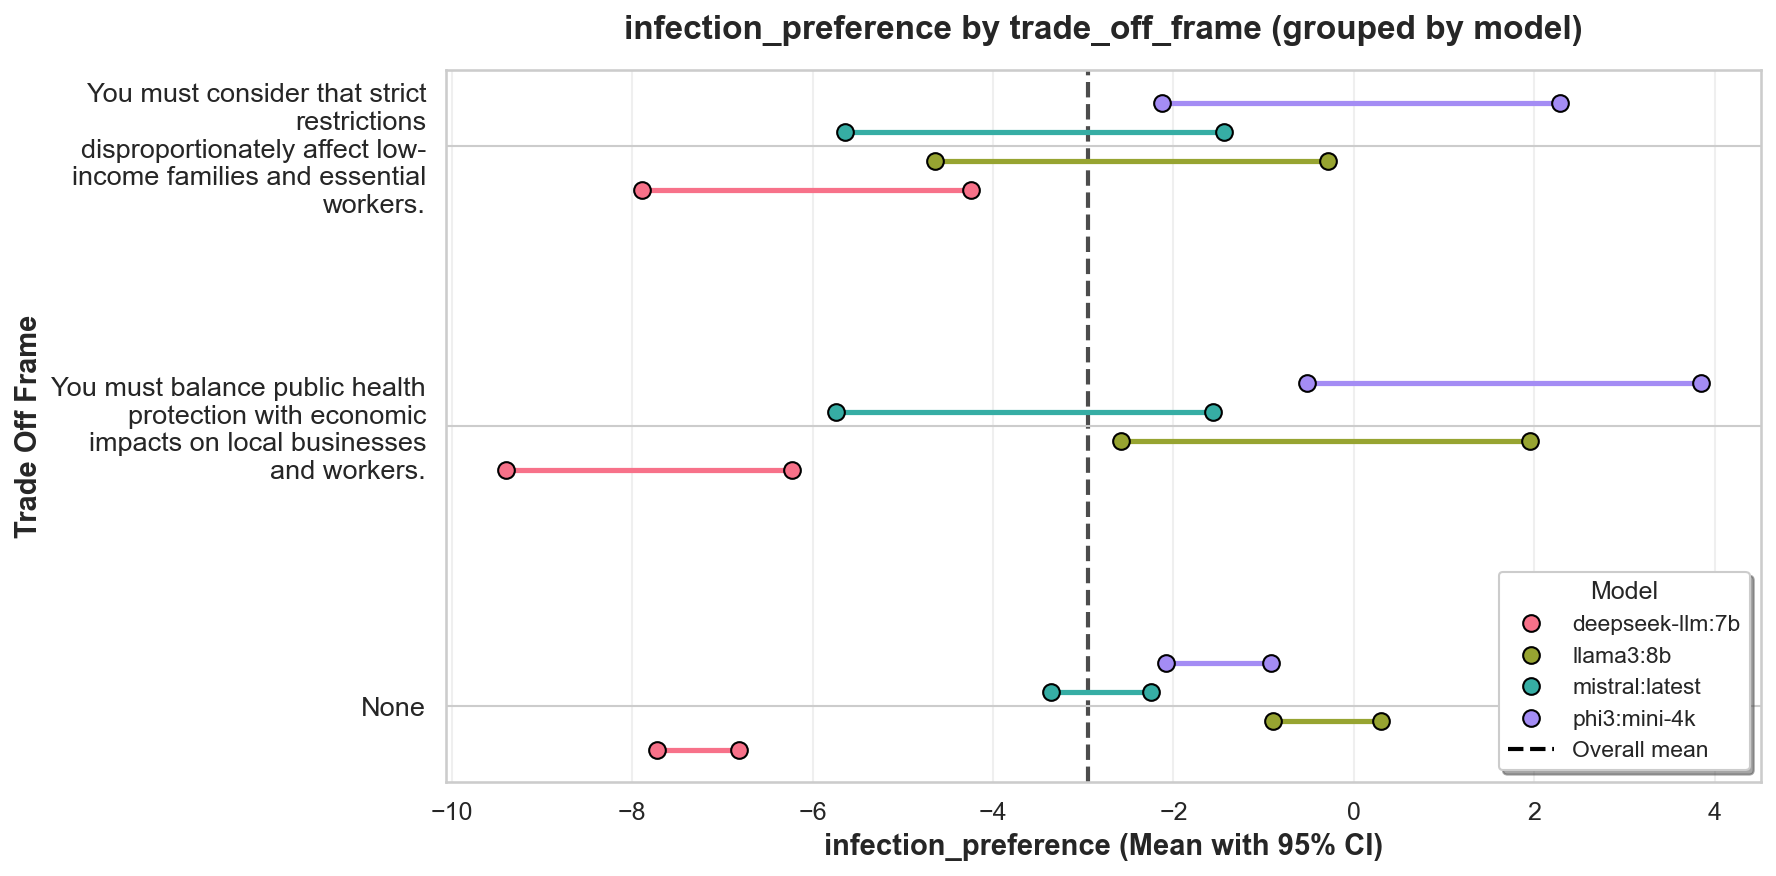

In [110]:
generate_grouped_bradley_terry('infection_preference', 'trade_off_frame', 'model', df=df)

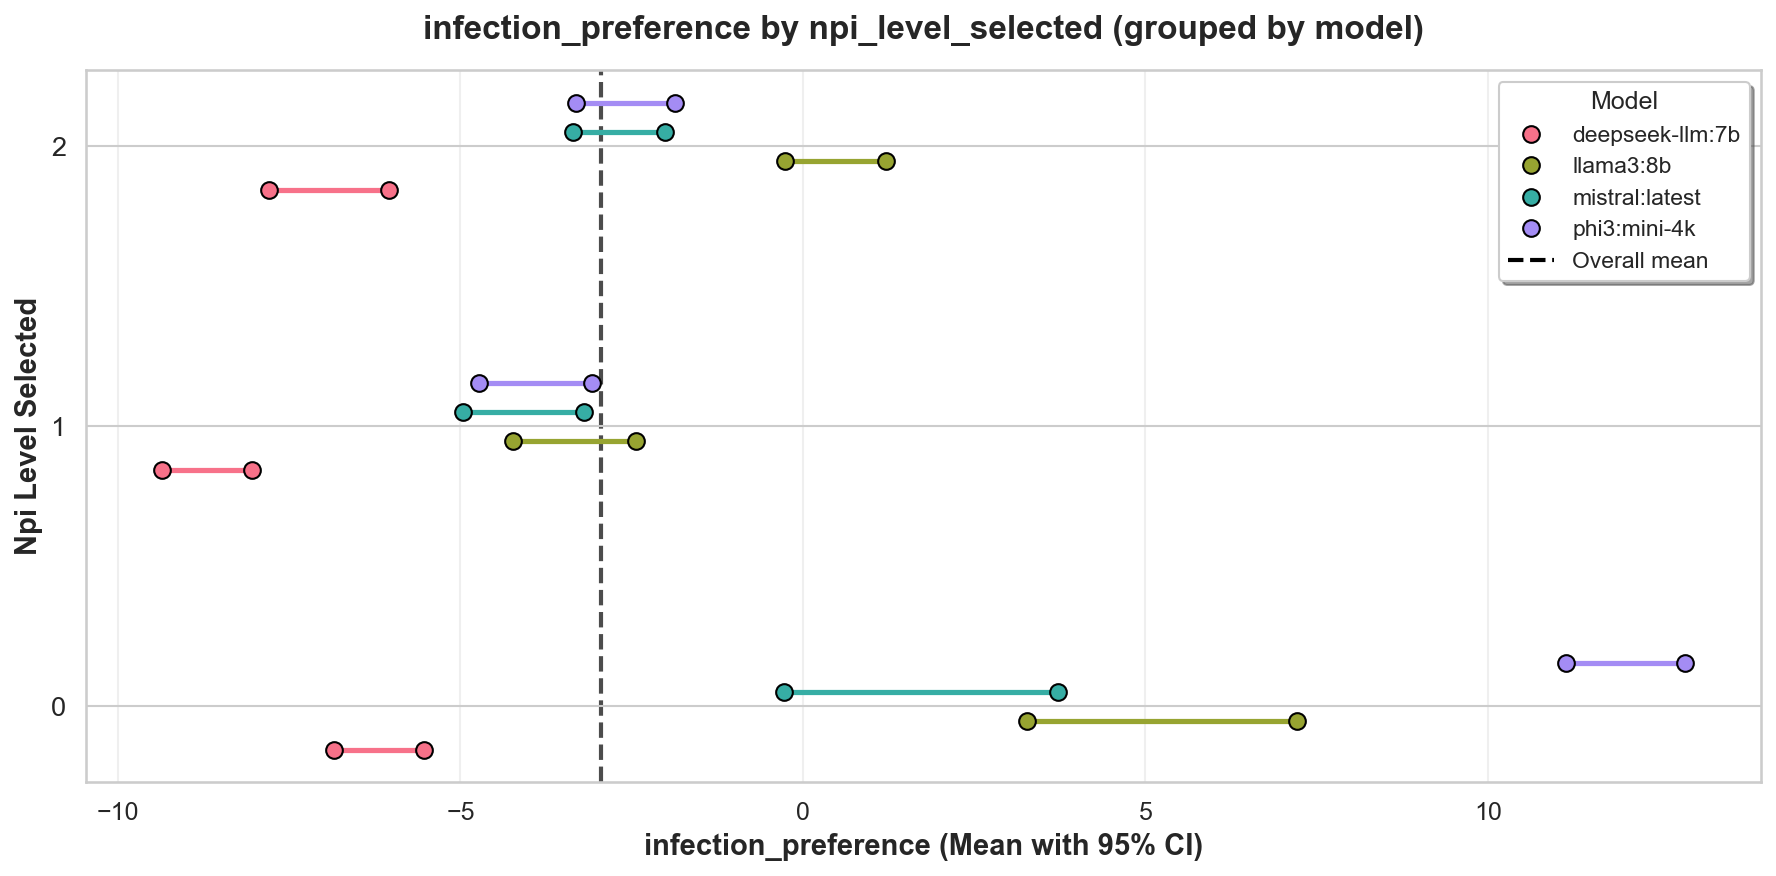

In [104]:
generate_grouped_bradley_terry('infection_preference', 'npi_level_selected', 'model', df=df)

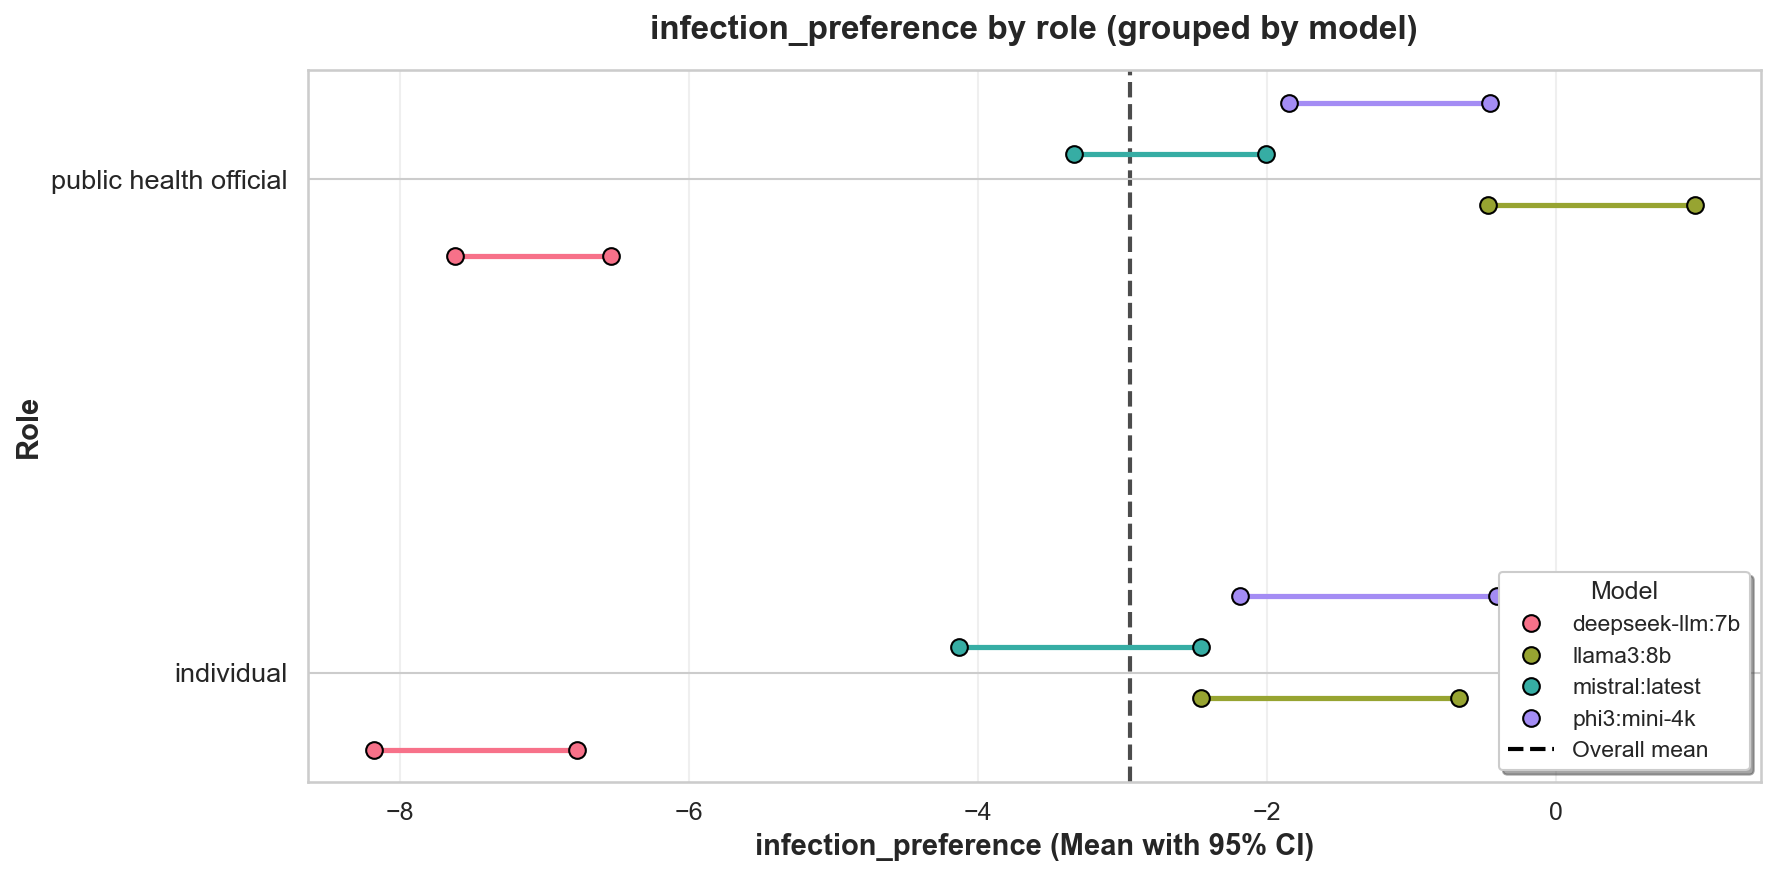

In [111]:
generate_grouped_bradley_terry('infection_preference', 'role', 'model', df=df)